# Reconnaissance de chiffres avec PyTorch

L'objectif est de construire et d'analyser un réseau de neurones qui reconnaît les chiffres manuscrits de 0 à 9 avec MNIST. Le fil conducteur est celui d'un travail de ML : comprendre les données, définir une expérience, concevoir un modèle, mesurer ses performances et analyser ses erreurs.

**À faire soi-même :** avant d'exécuter chaque étape, noter ce que l'on s'attend à observer et pourquoi. Les choix importants (architecture, taille des lots, nombre d'époques) sont explicités pour pouvoir être modifiés et comparés.

Les fichiers MNIST seront téléchargés par `torchvision` dans `data/MNIST/`. Le fichier déjà présent dans `data/` ne sera ni déplacé ni remplacé.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn

from number_recognition.data import (
    create_data_loaders,
    load_mnist,
    split_train_validation,
)
from number_recognition.model import DigitCNN, save_model
from number_recognition.training import train_model

SEED = 42
torch.manual_seed(SEED)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src" / "number_recognition").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = PROJECT_ROOT / "data"

print(f"PyTorch : {torch.__version__}")
print(f"Device  : {DEVICE}")
print(f"Dossier MNIST : {DATA_DIR / 'MNIST'}")

PyTorch : 2.11.0+cu128
Device  : cuda
Dossier MNIST : C:\Users\Hugo\OneDrive\Documents\prog\data\MNIST


## 1. Charger les données

`torchvision.datasets.MNIST` gère le téléchargement et la lecture du format IDX. La transformation `ToTensor` convertit les pixels en tenseurs flottants entre 0 et 1.

Le premier appel peut télécharger quelques dizaines de mégaoctets dans `data/MNIST/`. Les partitions officielles d'entraînement et de test sont chargées séparément ; nous créerons notre propre validation à partir du train.

In [ ]:
train_dataset, test_dataset = load_mnist(DATA_DIR)

print(f"Images d'entraînement : {len(train_dataset):,}")
print(f"Images de test        : {len(test_dataset):,}")
print(f"Forme d'une image     : {train_dataset[0][0].shape}")
print(f"Type du label         : {type(train_dataset[0][1]).__name__}")

Images d'entraînement : 60,000
Images de test        : 10,000
Forme d'une image     : torch.Size([1, 28, 28])
Type du label         : int


## 2. Comprendre la cible et la distribution

Avant d'entraîner, vérifions les dimensions, l'échelle des pixels et la répartition des classes. Une classification équilibrée ne nécessite pas les mêmes décisions qu'un jeu de données très déséquilibré.

In [14]:
example_image, example_label = train_dataset[0]

print(f"Image : forme={tuple(example_image.shape)}, dtype={example_image.dtype}")
print(f"Pixels : min={example_image.min().item():.1f}, max={example_image.max().item():.1f}")
print(f"Label : {example_label} (classe entière entre 0 et 9)")

class_counts = pd.DataFrame({
    "train": torch.bincount(train_dataset.targets, minlength=10).numpy(),
    "test": torch.bincount(test_dataset.targets, minlength=10).numpy(),
}, index=range(10))
class_counts.index.name = "chiffre"
class_counts

Image : forme=(1, 28, 28), dtype=torch.float32
Pixels : min=0.0, max=1.0
Label : 5 (classe entière entre 0 et 9)


,train,test
chiffre,,
0,5923,980
1,6742,1135
2,5958,1032
3,6131,1010
4,5842,982
5,5421,892
6,5918,958
7,6265,1028
8,5851,974


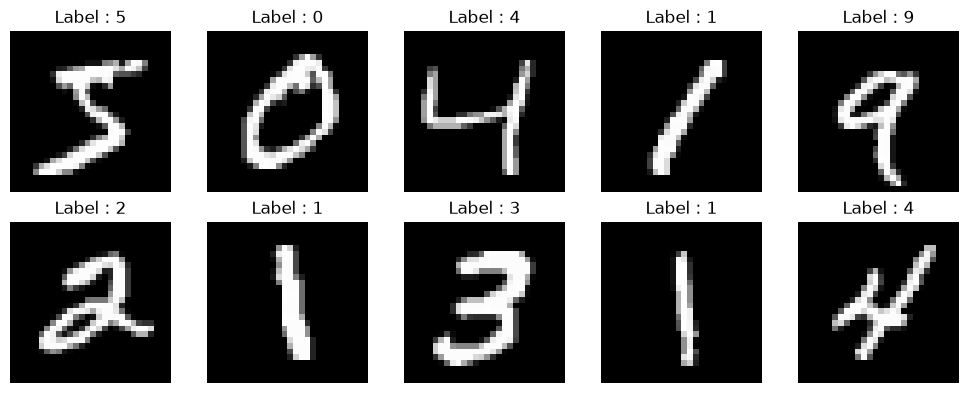

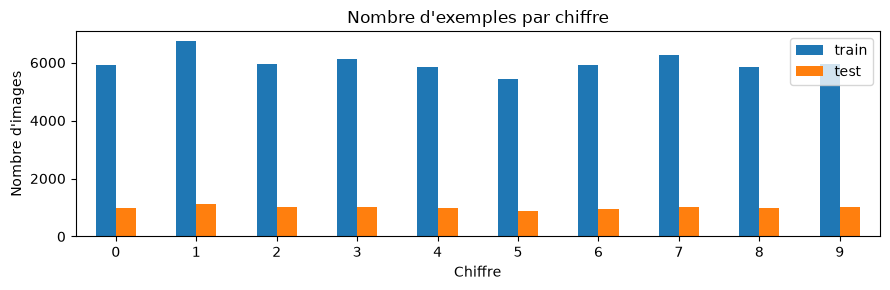

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    ax.imshow(train_dataset[digit][0].squeeze(0), cmap="gray")
    ax.set_title(f"Label : {train_dataset[digit][1]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

class_counts.plot(kind="bar", figsize=(9, 3), rot=0)
plt.title("Nombre d'exemples par chiffre")
plt.xlabel("Chiffre")
plt.ylabel("Nombre d'images")
plt.tight_layout()
plt.show()

## 3. Préparer l'expérience

On réserve 5 000 images d'entraînement pour la validation. Le jeu test officiel reste de côté jusqu'à la fin : l'utiliser pour choisir le modèle biaiserait l'estimation finale. `DataLoader` prépare des lots, et le mélange est appliqué seulement au train.

In [ ]:
VALIDATION_SIZE = 5_000
BATCH_SIZE = 128

train_subset, val_subset = split_train_validation(
    train_dataset,
    validation_size=VALIDATION_SIZE,
    seed=SEED,
)
train_loader, val_loader, test_loader = create_data_loaders(
    train_subset,
    val_subset,
    test_dataset,
    batch_size=BATCH_SIZE,
)

images, labels = next(iter(train_loader))
print(f"Tailles : train={len(train_subset):,}, validation={len(val_subset):,}, test={len(test_dataset):,}")
print(f"Un lot : images={tuple(images.shape)}, labels={tuple(labels.shape)}")
print(f"Classes dans ce lot : {labels[:16].tolist()}")

Tailles : train=55,000, validation=5,000, test=10,000
Un lot : images=(128, 1, 28, 28), labels=(128,)
Classes dans ce lot : [3, 1, 5, 0, 0, 8, 1, 1, 1, 6, 1, 9, 0, 1, 0, 2]


## 4. Concevoir le réseau convolutionnel

Le réseau respecte le parcours d'une image MNIST : deux blocs `Conv2d` + `ReLU` + `MaxPool2d` apprennent des motifs visuels et réduisent progressivement la résolution. Les cartes de caractéristiques passent de `1 × 28 × 28` à `32 × 14 × 14`, puis `64 × 7 × 7`.

`Flatten` transforme ces cartes en vecteur ; une couche dense de 128 neurones les combine avant la sortie de 10 logits, un par chiffre. Il n'y a pas de `softmax` final : `CrossEntropyLoss` l'intègre déjà de façon stable.

In [ ]:
model = DigitCNN().to(DEVICE)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

sample_images = images.to(DEVICE)
feature_maps = model.features(sample_images)
sample_logits = model(sample_images)
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(f"Entrée du modèle : {tuple(images.shape)}")
print(f"Après convolutions/pooling : {tuple(feature_maps.shape)}")
print(f"Sortie du modèle : {tuple(sample_logits.shape)} (lot, 10 logits)")
print(f"Paramètres entraînables : {trainable_parameters:,}")

Entrée du modèle : (128, 1, 28, 28)
Après convolutions/pooling : (128, 64, 7, 7)
Sortie du modèle : (128, 10) (lot, 10 logits)
Paramètres entraînables : 421,642


## 5. Entraîner et suivre les métriques

La fonction ci-dessous fait une passe complète sur les lots. En mode entraînement, elle calcule les gradients et met à jour les poids ; en validation, elle désactive ces opérations. La perte moyenne est pondérée par le nombre d'images de chaque lot.

In [ ]:
EPOCHS = 8
LEARNING_RATE = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_function = nn.CrossEntropyLoss()

history = pd.DataFrame(
    train_model(
        model,
        train_loader,
        val_loader,
        optimizer=optimizer,
        epochs=EPOCHS,
        device=DEVICE,
        loss_function=loss_function,
    )
)
history

Époque 1/8 | train loss=0.2691, acc=0.922 | val loss=0.0861, acc=0.975
Époque 2/8 | train loss=0.0607, acc=0.982 | val loss=0.0521, acc=0.985
Époque 3/8 | train loss=0.0426, acc=0.987 | val loss=0.0474, acc=0.985
Époque 4/8 | train loss=0.0327, acc=0.990 | val loss=0.0408, acc=0.988
Époque 5/8 | train loss=0.0256, acc=0.992 | val loss=0.0460, acc=0.985
Époque 6/8 | train loss=0.0204, acc=0.994 | val loss=0.0405, acc=0.989
Époque 7/8 | train loss=0.0158, acc=0.995 | val loss=0.0339, acc=0.990
Époque 8/8 | train loss=0.0134, acc=0.996 | val loss=0.0392, acc=0.988


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.269124,0.922309,0.086098,0.9752
1,2,0.060675,0.981527,0.052124,0.9848
2,3,0.042640,0.986782,0.047391,0.9854
3,4,0.032692,0.989836,0.040822,0.9880
4,5,0.025619,0.991782,0.045990,0.9850
5,6,0.020427,0.993673,0.040521,0.9886
6,7,0.015818,0.995218,0.033871,0.9898
7,8,0.013405,0.995964,0.039220,0.9884


In [ ]:
MODEL_PATH = PROJECT_ROOT / "models" / "digit_cnn.pth"
checkpoint_path = save_model(model, MODEL_PATH)
print(f"Poids du modèle enregistrés dans : {checkpoint_path}")

Poids du modèle enregistrés dans : C:\Users\Hugo\OneDrive\Documents\prog\models\digit_cnn.pth


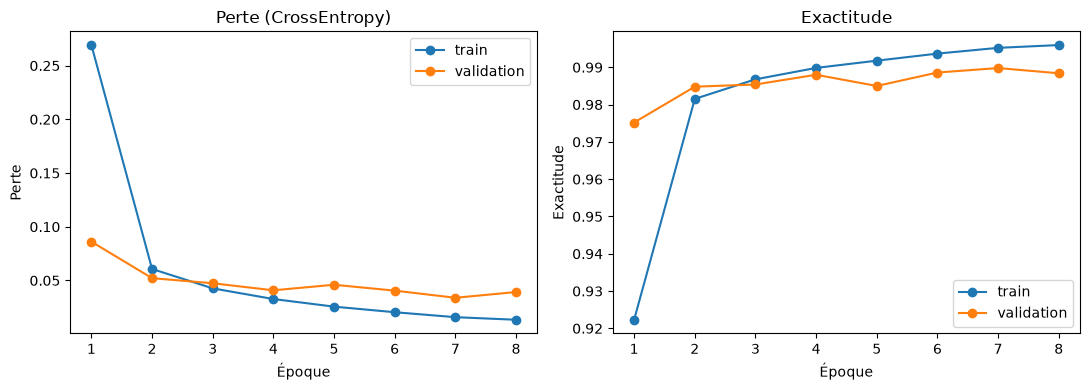

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["epoch"], history["train_loss"], marker="o", label="train")
axes[0].plot(history["epoch"], history["val_loss"], marker="o", label="validation")
axes[0].set_title("Perte (CrossEntropy)")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Perte")
axes[0].legend()

axes[1].plot(history["epoch"], history["train_accuracy"], marker="o", label="train")
axes[1].plot(history["epoch"], history["val_accuracy"], marker="o", label="validation")
axes[1].set_title("Exactitude")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Exactitude")
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Évaluer une seule fois sur le test

Après avoir observé la validation, on mesure la performance finale sur le jeu test officiel. La matrice de confusion indique quelles paires de chiffres sont confondues ; l'exactitude globale seule ne montre pas ces écarts.

Exactitude test : 0.9897

Rapport par classe :
              precision    recall  f1-score   support

           0      0.987     0.999     0.993       980
           1      0.992     0.997     0.995      1135
           2      0.984     0.995     0.989      1032
           3      0.991     0.993     0.992      1010
           4      0.996     0.985     0.990       982
           5      0.985     0.988     0.987       892
           6      0.994     0.986     0.990       958
           7      0.990     0.987     0.989      1028
           8      0.989     0.991     0.990       974
           9      0.989     0.974     0.982      1009

    accuracy                          0.990     10000
   macro avg      0.990     0.990     0.990     10000
weighted avg      0.990     0.990     0.990     10000



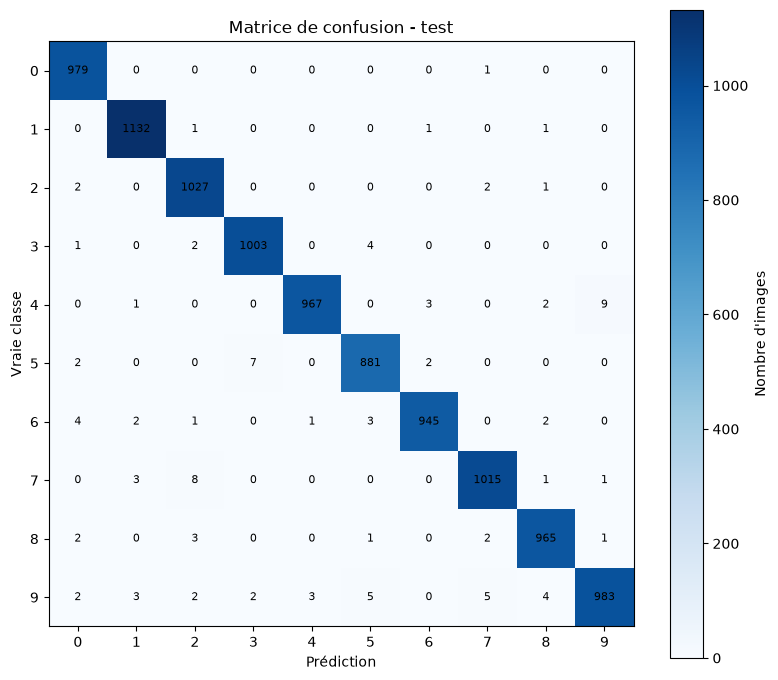

In [22]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

model.eval()
y_true = []
y_pred = []

with torch.inference_mode():
    for batch_images, batch_labels in test_loader:
        logits = model(batch_images.to(DEVICE))
        predictions = logits.argmax(dim=1).cpu()
        y_pred.extend(predictions.tolist())
        y_true.extend(batch_labels.tolist())

print(f"Exactitude test : {accuracy_score(y_true, y_pred):.4f}")
print("\nRapport par classe :")
print(classification_report(y_true, y_pred, digits=3, zero_division=0))

confusion = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(confusion, cmap="Blues")
ax.set(title="Matrice de confusion - test", xlabel="Prédiction", ylabel="Vraie classe")
ax.set_xticks(range(10))
ax.set_yticks(range(10))
fig.colorbar(image, ax=ax, label="Nombre d'images")
for row in range(10):
    for column in range(10):
        ax.text(column, row, confusion[row, column], ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()

## 7. Examiner les erreurs

Les erreurs sont souvent plus instructives que le score moyen. Regardons quelques images mal classées et cherchons des motifs : écriture ambiguë, traits peu visibles, ou confusion récurrente entre deux chiffres.

Erreurs : 103 sur 10000 images


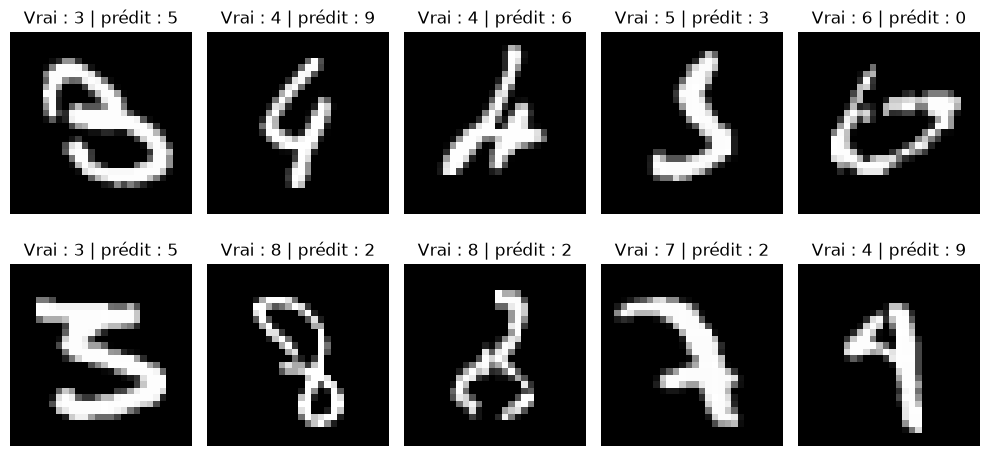

In [23]:
wrong_indices = [index for index, (truth, prediction) in enumerate(zip(y_true, y_pred)) if truth != prediction]
print(f"Erreurs : {len(wrong_indices)} sur {len(y_true)} images")

examples_to_show = wrong_indices[:10]
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, index in zip(axes.flat, examples_to_show):
    image, truth = test_dataset[index]
    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(f"Vrai : {truth} | prédit : {y_pred[index]}")
    ax.axis("off")
for ax in axes.flat[len(examples_to_show):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Bilan d'expérience

À compléter après exécution :

- Quelle paire de chiffres est la plus souvent confondue ? Pourquoi ?
- L'écart entre exactitude train et validation augmente-t-il avec les époques ? Que suggère-t-il ?
- Quel changement tester en premier : taille de la couche cachée, taux d'apprentissage, nombre d'époques ou architecture CNN ? Formule une hypothèse et ne change qu'un facteur à la fois.
- Note la métrique de validation avant chaque changement pour comparer les expériences proprement.